# MATH 70116, Deep Learning
Autumn 2026

Lecturer: Tom Hadfield


### Network initialisation

As seen previously, vanishing and exploding gradients cause difficulties during neural network training.

Vanishing gradients lead to very slow (or zero) learning in earlier layers

Exploding gradients lead to unstable updates and diverging loss

Training may converge poorly or fail completely

Avoiding these problems requires careful tuning of learning rates and weight initialisation

The choice of activation function is important.

We explored this in the notebook <code>Vanishing_and_exploding_gradients.ipynb</code>

In this notebook we look at the importance of initialising the model parameters correctly. 

## Backpropagation equations:

### $z^{i+1} = W^{i+1} a^i + b^{i+1}$     $\quad \quad i = 0,1, \ldots, r-1$
### Layerwise activations $a^i$:
### $a^0 = x \quad \quad$ initial input
### $a^i = \sigma(z^i)$ $\quad \quad i = 1, \ldots, r$
### $a^r$ output

### Define the "error" of neuron $j$ in layer $i$ ($i = 1, \ldots r$) as $$\delta_j^i = {\frac{\partial L}{\partial z_j^i}}$$
### BP1. For the output layer ($i = r$) : $\delta_j^r = {\frac{\partial L}{\partial z_j^r}} = {\frac{\partial L}{\partial a_j^r}} \sigma' (z_j^r)$
### BP2. For $i < r$ : $\quad \delta_j^i = ((W^{i+1})^t \delta^{i+1} )_j \sigma' (z_j^i) = \sum_k \delta_k^{i+1} W^{i+1}_{kj} \sigma' (z_j^i)$
### BP3. Weights : $\quad {\frac{\partial L}{\partial W_{jk}^i}} = a_k^{i-1} \delta_j^i$
### BP4. Biases : $\quad {\frac{\partial L}{\partial b_j^i}} = \delta_j^i$

In [1]:
import numpy as np
import numpy.random as npr
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
plt.style.use('ggplot')

import sklearn
from sklearn.model_selection import train_test_split

### Create a simple dataset

Binary classification dataset.

Keep the data simple so we can focus on the gradient behaviour.

Prevent data complexity from hiding gradient issues

In [2]:
np.random.seed(42)

X = np.random.randn(2000, 2)
y = (X[:, 0] + X[:, 1] > 0).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [3]:
for xx in [X_train, X_test, y_train, y_test]:
    print(type(xx), xx.shape)

<class 'numpy.ndarray'> (1600, 2)
<class 'numpy.ndarray'> (400, 2)
<class 'numpy.ndarray'> (1600,)
<class 'numpy.ndarray'> (400,)


### Visualise the data

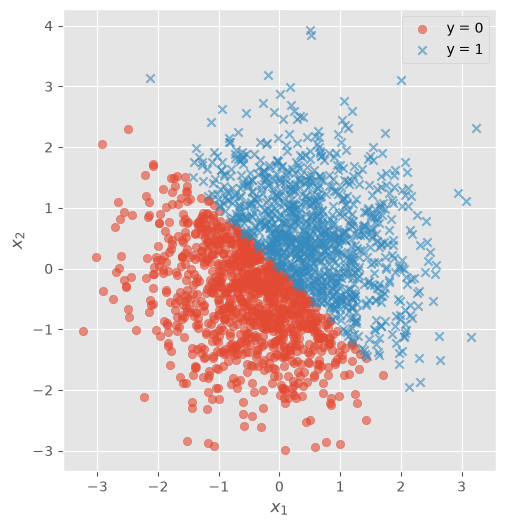

In [4]:
fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(X[y == 0, 0], X[y == 0, 1], marker='o', alpha=0.6, label='y = 0')
ax.scatter(X[y == 1, 0], X[y == 1, 1], marker='x', alpha=0.6, label='y = 1')

ax.set_xlabel('$x_1$')
ax.set_ylabel('$x_2$')
ax.set_aspect('equal')
ax.legend()
plt.show()

Previously we compared the Sigmoid and ReLU activation functions.

We established that ReLU performed the best - why?

This time, we fix the activation function (ReLU) and experiment with different initialisations

We use many layers to amplify vanishing gradient effects

In [5]:
def build_model(activation = nn.ReLU(), num_layers=10, hidden_dim = 32):
    
    f = nn.Sequential()
    f.add_module("input", nn.Linear(2, hidden_dim))
    f.add_module("act_0", activation)
    
    for i in range(1,num_layers):
        layer_name = "dense" + str(i)
        act_name = "act" + str(i)
        f.add_module(layer_name, nn.Linear(hidden_dim, hidden_dim))
        f.add_module(act_name, activation)
        
    f.add_module("output", nn.Linear(hidden_dim, 1))
    f.add_module("act_output", nn.Sigmoid()) # final activation must be Sigmoid

    return f

### 1. Set all initial weights and biases to zero

In [6]:
activation = nn.ReLU()
num_layers = 10
hidden_dim = 32

f = build_model(activation, num_layers, hidden_dim)

In [8]:
#print(len(f))
num_layers = int(len(f)/2)
for i in range(num_layers):
    zero_weight = np.zeros(f[2*i].weight.shape)
    zero_bias = np.zeros(f[2*i].bias.shape)

    with torch.no_grad():
        f[2*i].weight.copy_(torch.from_numpy(zero_weight).float())
        f[2*i].bias.copy_(torch.from_numpy(zero_bias).float())

In [9]:
# sanity check - pick a random layer, check that weights and biases are all zero
k = np.random.randint(int(len(f)/2))
print("k = ", k)
this_w_sum_sqrd = torch.sum(f[2*k].weight**2).detach().item()
print(k, "sum weights^2 = ", this_w_sum_sqrd)
this_b_sum_sqrd = torch.sum(f[2*k].bias**2).detach().item()
print(k, "sum biases^2 = ", this_b_sum_sqrd)

k =  7
7 sum weights^2 =  0.0
7 sum biases^2 =  0.0


In [10]:
eta = 0.001
optimizer = torch.optim.Adam(f.parameters(), lr=eta)
loss_fn = nn.BCELoss()

In [14]:
epochs = 10

train_zero = train_model(
    f,
    X_train,
    y_train,
    loss_fn,
    optimizer,
    epochs,
    batch_size=32,
    validation_split=0.2,
    verbose_every=1
)

n_total =  1600 n_val =  320 n_train =  1280
Epoch 1/10, loss: 0.6932, val_loss: 0.6933
Epoch 2/10, loss: 0.6931, val_loss: 0.6933
Epoch 3/10, loss: 0.6931, val_loss: 0.6933
Epoch 4/10, loss: 0.6931, val_loss: 0.6933
Epoch 5/10, loss: 0.6931, val_loss: 0.6933
Epoch 6/10, loss: 0.6932, val_loss: 0.6935
Epoch 7/10, loss: 0.6931, val_loss: 0.6935
Epoch 8/10, loss: 0.6931, val_loss: 0.6935
Epoch 9/10, loss: 0.6931, val_loss: 0.6935
Epoch 10/10, loss: 0.6931, val_loss: 0.6935


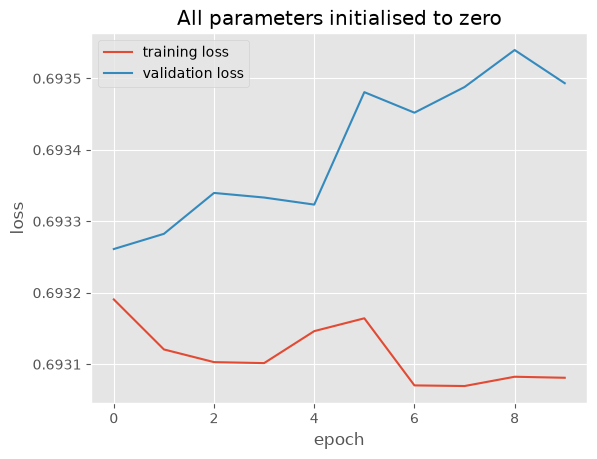

In [15]:
loss_vals = train_zero["loss"]
val_loss_vals = train_zero["val_loss"]
epoch_vals = range(len(loss_vals))

plt.plot(epoch_vals, loss_vals, label = "training loss")
plt.plot(epoch_vals, val_loss_vals, label = "validation loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.title("All parameters initialised to zero")
plt.show()

ppred.shape =  (361201, 1)
ppred.shape =  (601, 601)
max =  0.50479937
min =  0.50479937


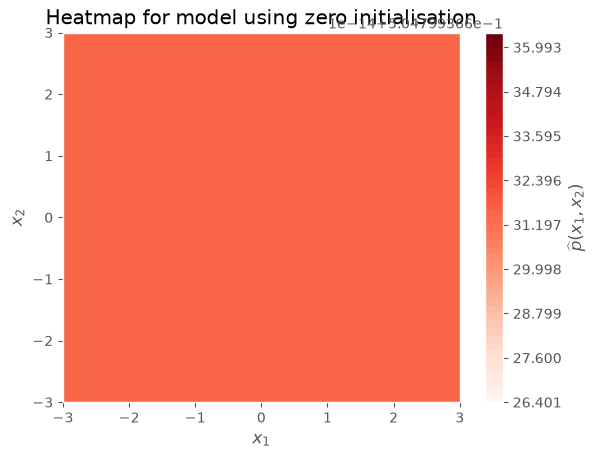

In [16]:
# num points in grid
this_num = 6 * 100 + 1

grid = np.linspace(-3., 3., num=this_num)
X_1g, X_2g = np.meshgrid(grid, grid)

X_1gf = np.reshape(X_1g, (this_num*this_num, 1))
X_2gf = np.reshape(X_2g, (this_num*this_num, 1))
Xf = np.concatenate((X_1gf, X_2gf), 1)

ppred = model_predict(f,Xf)

print("ppred.shape = ", ppred.shape)

ppred = np.reshape(ppred,(this_num, this_num))
print("ppred.shape = ", ppred.shape)
print("max = ", np.max(ppred))
print("min = ", np.min(ppred))

plt.contourf(X_1g, X_2g, ppred, 50, cmap="Reds")
cbar = plt.colorbar()
cbar.ax.set_ylabel(r"$\widehat{p}(x_1,x_2)$")
plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$")
plt.title("Heatmap for model using zero initialisation")
plt.show()

In [17]:
# inspect layer by layer:
for k in range(int(len(f)/2)):
    #print("k = ", k)
    this_w_sum_sqrd = torch.sum(f[2*k].weight**2).detach().item()
    print(k, "sum weights^2 = ", this_w_sum_sqrd)
    this_b_sum_sqrd = torch.sum(f[2*k].bias**2).detach().item()
    print(k, "sum biases^2 = ", this_b_sum_sqrd)

0 sum weights^2 =  0.0
0 sum biases^2 =  0.0
1 sum weights^2 =  0.0
1 sum biases^2 =  0.0
2 sum weights^2 =  0.0
2 sum biases^2 =  0.0
3 sum weights^2 =  0.0
3 sum biases^2 =  0.0
4 sum weights^2 =  0.0
4 sum biases^2 =  0.0
5 sum weights^2 =  0.0
5 sum biases^2 =  0.0
6 sum weights^2 =  0.0
6 sum biases^2 =  0.0
7 sum weights^2 =  0.0
7 sum biases^2 =  0.0
8 sum weights^2 =  0.0
8 sum biases^2 =  0.0
9 sum weights^2 =  0.0
9 sum biases^2 =  0.0
10 sum weights^2 =  0.0
10 sum biases^2 =  0.0003685624396894127


In [18]:
k = int(len(f)/2) - 1
print("final layer bias = ", f[2*k].bias)

final layer bias =  Parameter containing:
tensor([0.0192], requires_grad=True)


### Exercise : if you increase the learning rate / train for longer, does the model start to train?

### 2. Set all initial weights and biases to $N(0,1)$

In [19]:
activation = nn.ReLU()
num_layers = 10
hidden_dim = 32

f2 = build_model(activation, num_layers, hidden_dim)

In [20]:
# sanity check
print(torch.is_grad_enabled())                      # should be True
for name, p in f2.named_parameters():
    print(name, p.requires_grad)  

True
input.weight True
input.bias True
dense1.weight True
dense1.bias True
dense2.weight True
dense2.bias True
dense3.weight True
dense3.bias True
dense4.weight True
dense4.bias True
dense5.weight True
dense5.bias True
dense6.weight True
dense6.bias True
dense7.weight True
dense7.bias True
dense8.weight True
dense8.bias True
dense9.weight True
dense9.bias True
output.weight True
output.bias True


In [21]:
num_layers = int(len(f2)/2)

mean = 0.0
# std controls the scale of the initialisation
std = 1.0 #0.7 #1.0 #0.1

for i in range(num_layers):
    normal_weight = np.random.normal(mean, std, f2[2*i].weight.shape)
    normal_bias = np.random.normal(mean, std, f2[2*i].bias.shape)

    with torch.no_grad():
        f2[2*i].weight.copy_(torch.from_numpy(normal_weight).float())
        f2[2*i].bias.copy_(torch.from_numpy(normal_bias).float())

In [ ]:
print(torch.is_grad_enabled())                      # should be True
for name, p in f2.named_parameters():
    print(name, p.requires_grad)  

In [22]:
# inspect layer by layer:
for k in range(int(len(f2)/2)):
    this_w_sum_sqrd = torch.sum(f2[2*k].weight**2).detach().item()
    print(k, "sum weights^2 = ", this_w_sum_sqrd)
    this_b_sum_sqrd = torch.sum(f2[2*k].bias**2).detach().item()
    print(k, "sum biases^2 = ", this_b_sum_sqrd)

0 sum weights^2 =  59.89063262939453
0 sum biases^2 =  37.6004638671875
1 sum weights^2 =  980.923828125
1 sum biases^2 =  20.177288055419922
2 sum weights^2 =  1056.99755859375
2 sum biases^2 =  35.24063491821289
3 sum weights^2 =  1005.475341796875
3 sum biases^2 =  37.51642608642578
4 sum weights^2 =  1048.5648193359375
4 sum biases^2 =  24.85070037841797
5 sum weights^2 =  988.4210205078125
5 sum biases^2 =  37.29429244995117
6 sum weights^2 =  1065.845458984375
6 sum biases^2 =  42.576988220214844
7 sum weights^2 =  1012.469482421875
7 sum biases^2 =  24.277873992919922
8 sum weights^2 =  1049.533447265625
8 sum biases^2 =  24.7052059173584
9 sum weights^2 =  1007.5294799804688
9 sum biases^2 =  25.320728302001953
10 sum weights^2 =  32.57014083862305
10 sum biases^2 =  0.3654446601867676


In [23]:
eta = 0.001
optimizer = torch.optim.Adam(f2.parameters(), lr=eta)
loss_fn = nn.BCELoss()

In [24]:
epochs = 10

train_normal = train_model(
    f2,
    X_train,
    y_train,
    loss_fn,
    optimizer,
    epochs,
    batch_size=32,
    validation_split=0.2,
    verbose_every=1
)

n_total =  1600 n_val =  320 n_train =  1280
Epoch 1/10, loss: 52.5781, val_loss: 50.9375
Epoch 2/10, loss: 52.5781, val_loss: 50.9375
Epoch 3/10, loss: 52.5781, val_loss: 50.9375
Epoch 4/10, loss: 52.5781, val_loss: 50.9375
Epoch 5/10, loss: 52.5781, val_loss: 50.9375
Epoch 6/10, loss: 52.5781, val_loss: 50.9375
Epoch 7/10, loss: 52.5781, val_loss: 50.9375
Epoch 8/10, loss: 52.5781, val_loss: 50.9375
Epoch 9/10, loss: 52.5781, val_loss: 50.9375
Epoch 10/10, loss: 52.5781, val_loss: 50.9375


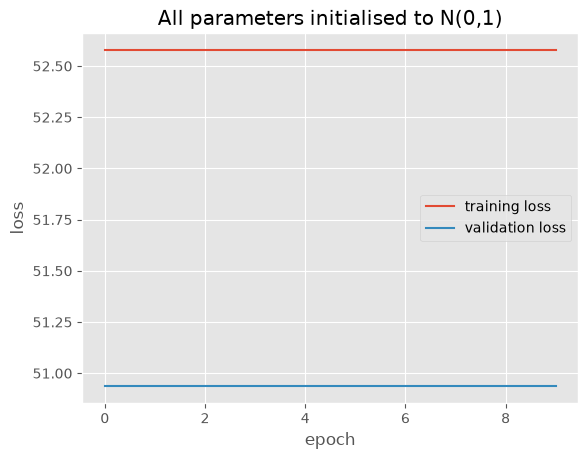

In [25]:
loss_vals = train_normal["loss"]
val_loss_vals = train_normal["val_loss"]
epoch_vals = range(len(loss_vals))

plt.plot(epoch_vals, loss_vals, label = "training loss")
plt.plot(epoch_vals, val_loss_vals, label = "validation loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.title("All parameters initialised to N(0,1)")
plt.show()

ppred.shape =  (361201, 1)
ppred.shape =  (601, 601)
max =  1.0
min =  0.0


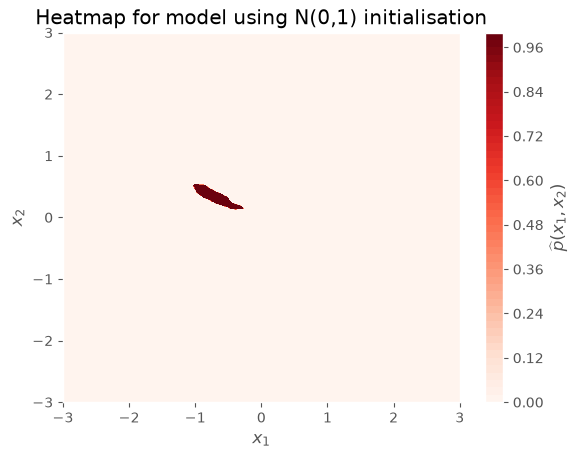

In [26]:
# num points in grid
this_num = 6 * 100 + 1

grid = np.linspace(-3., 3., num=this_num)
X_1g, X_2g = np.meshgrid(grid, grid)

X_1gf = np.reshape(X_1g, (this_num*this_num, 1))
X_2gf = np.reshape(X_2g, (this_num*this_num, 1))
Xf = np.concatenate((X_1gf, X_2gf), 1)

ppred = model_predict(f2,Xf)

print("ppred.shape = ", ppred.shape)

ppred = np.reshape(ppred,(this_num, this_num))
print("ppred.shape = ", ppred.shape)
print("max = ", np.max(ppred))
print("min = ", np.min(ppred))

plt.contourf(X_1g, X_2g, ppred, 50, cmap="Reds")
cbar = plt.colorbar()
cbar.ax.set_ylabel(r"$\widehat{p}(x_1,x_2)$")
plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$")
plt.title("Heatmap for model using N(0,1) initialisation")
plt.show()

In [27]:
# inspect layer by layer, again:
for k in range(int(len(f2)/2)):
    this_w_sum_sqrd = torch.sum(f2[2*k].weight**2).detach().item()
    print(k, "sum weights^2 = ", this_w_sum_sqrd)
    this_b_sum_sqrd = torch.sum(f2[2*k].bias**2).detach().item()
    print(k, "sum biases^2 = ", this_b_sum_sqrd)

0 sum weights^2 =  59.89063262939453
0 sum biases^2 =  37.6004638671875
1 sum weights^2 =  980.923828125
1 sum biases^2 =  20.177288055419922
2 sum weights^2 =  1056.99755859375
2 sum biases^2 =  35.24063491821289
3 sum weights^2 =  1005.475341796875
3 sum biases^2 =  37.51642608642578
4 sum weights^2 =  1048.5648193359375
4 sum biases^2 =  24.85070037841797
5 sum weights^2 =  988.4210205078125
5 sum biases^2 =  37.29429244995117
6 sum weights^2 =  1065.845458984375
6 sum biases^2 =  42.576988220214844
7 sum weights^2 =  1012.469482421875
7 sum biases^2 =  24.277873992919922
8 sum weights^2 =  1049.533447265625
8 sum biases^2 =  24.7052059173584
9 sum weights^2 =  1007.5294799804688
9 sum biases^2 =  25.320728302001953
10 sum weights^2 =  32.57014083862305
10 sum biases^2 =  0.3654446601867676


### Exercise: try with smaller scales: std = 0.01, 0.1, 0.5

### Xavier (Glorot) initialisation
*Understanding the difficulty of training deep feedforward neural networks*, Glorot, X. & Bengio, Y. (2010).
$$W \sim U[-a,a], \quad \quad a = \sqrt{\frac{6}{{fan}_{in} + {fan}_{out}}}$$

In [28]:
# Xavier
activation = nn.ReLU()
num_layers = 10
hidden_dim = 32

f_x = build_model(activation, num_layers, hidden_dim)

In [29]:
num_layers = int(len(f_x)/2)
for i in range(num_layers):
    fan_out, fan_in = f_x[2*i].weight.shape
    print(i, f_x[2*i].weight.shape, fan_in, fan_out)

0 torch.Size([32, 2]) 2 32
1 torch.Size([32, 32]) 32 32
2 torch.Size([32, 32]) 32 32
3 torch.Size([32, 32]) 32 32
4 torch.Size([32, 32]) 32 32
5 torch.Size([32, 32]) 32 32
6 torch.Size([32, 32]) 32 32
7 torch.Size([32, 32]) 32 32
8 torch.Size([32, 32]) 32 32
9 torch.Size([32, 32]) 32 32
10 torch.Size([1, 32]) 32 1


In [30]:
import math

num_layers = int(len(f_x)/2)

for i in range(num_layers):
    fan_out, fan_in = f_x[2*i].weight.shape
    x_a = math.sqrt(6.0 / (fan_in + fan_out)) 
    x_weight = np.random.uniform(-1.0 * x_a, x_a, f_x[2*i].weight.shape)
    x_bias = np.random.uniform(-1.0 * x_a, x_a, f_x[2*i].bias.shape)

    with torch.no_grad():
        f_x[2*i].weight.copy_(torch.from_numpy(x_weight).float())
        f_x[2*i].bias.copy_(torch.from_numpy(x_bias).float())

In [31]:
eta = 0.001
optimizer = torch.optim.Adam(f_x.parameters(), lr=eta)
loss_fn = nn.BCELoss()

In [32]:
epochs = 10

train_normal = train_model(
    f_x,
    X_train,
    y_train,
    loss_fn,
    optimizer,
    epochs,
    batch_size=32,
    validation_split=0.2,
    verbose_every=1
)

n_total =  1600 n_val =  320 n_train =  1280
Epoch 1/10, loss: 0.6245, val_loss: 0.4049
Epoch 2/10, loss: 0.1322, val_loss: 0.0592
Epoch 3/10, loss: 0.0300, val_loss: 0.0470
Epoch 4/10, loss: 0.0261, val_loss: 0.0636
Epoch 5/10, loss: 0.0286, val_loss: 0.0091
Epoch 6/10, loss: 0.0153, val_loss: 0.0053
Epoch 7/10, loss: 0.0245, val_loss: 0.0094
Epoch 8/10, loss: 0.0230, val_loss: 0.0079
Epoch 9/10, loss: 0.0123, val_loss: 0.0072
Epoch 10/10, loss: 0.0173, val_loss: 0.0077


ppred.shape =  (361201, 1)
ppred.shape =  (601, 601)
max =  1.0
min =  6.636667e-20


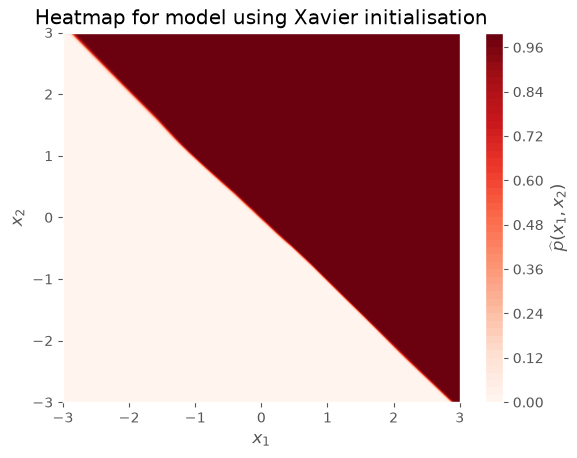

In [33]:
# num points in grid
this_num = 6 * 100 + 1

grid = np.linspace(-3., 3., num=this_num)
X_1g, X_2g = np.meshgrid(grid, grid)

X_1gf = np.reshape(X_1g, (this_num*this_num, 1))
X_2gf = np.reshape(X_2g, (this_num*this_num, 1))
Xf = np.concatenate((X_1gf, X_2gf), 1)

ppred = model_predict(f_x,Xf)

print("ppred.shape = ", ppred.shape)

ppred = np.reshape(ppred,(this_num, this_num))
print("ppred.shape = ", ppred.shape)
print("max = ", np.max(ppred))
print("min = ", np.min(ppred))

plt.contourf(X_1g, X_2g, ppred, 50, cmap="Reds")
cbar = plt.colorbar()
cbar.ax.set_ylabel(r"$\widehat{p}(x_1,x_2)$")
plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$")
plt.title("Heatmap for model using Xavier initialisation")
plt.show()

### Kaiming initialisation

*Delving Deep into Rectifiers: Surpassing Human-Level Performance on ImageNet Classification*,
Kaiming He et al. https://arxiv.org/abs/1502.01852

$$W \sim N(0,\sigma), \quad \quad \sigma = \sqrt{\frac{2}{{fan}_{in}}}$$

In [35]:
activation = nn.ReLU()
num_layers = 10
hidden_dim = 32

f_k = build_model(activation, num_layers, hidden_dim)

In [36]:
import math

num_layers = int(len(f_k)/2)

for i in range(num_layers):
    fan_out, fan_in = f_k[2*i].weight.shape
    k_sigma = math.sqrt(2 / fan_in)
    k_weight = np.random.normal(0., k_sigma, f_k[2*i].weight.shape)
    k_bias = np.random.normal(0., k_sigma, f_k[2*i].bias.shape)

    with torch.no_grad():
        f_k[2*i].weight.copy_(torch.from_numpy(k_weight).float())
        f_k[2*i].bias.copy_(torch.from_numpy(k_bias).float())

In [37]:
eta = 0.001
optimizer = torch.optim.Adam(f_k.parameters(), lr=eta)
loss_fn = nn.BCELoss()

In [38]:
epochs = 10

train_normal = train_model(
    f_k,
    X_train,
    y_train,
    loss_fn,
    optimizer,
    epochs,
    batch_size=32,
    validation_split=0.2,
    verbose_every=1
)

n_total =  1600 n_val =  320 n_train =  1280
Epoch 1/10, loss: 0.5417, val_loss: 0.1633
Epoch 2/10, loss: 0.0932, val_loss: 0.0370
Epoch 3/10, loss: 0.0370, val_loss: 0.0145
Epoch 4/10, loss: 0.0376, val_loss: 0.0240
Epoch 5/10, loss: 0.0320, val_loss: 0.0110
Epoch 6/10, loss: 0.0262, val_loss: 0.0484
Epoch 7/10, loss: 0.0242, val_loss: 0.0287
Epoch 8/10, loss: 0.0351, val_loss: 0.0283
Epoch 9/10, loss: 0.0352, val_loss: 0.0366
Epoch 10/10, loss: 0.0367, val_loss: 0.0154


ppred.shape =  (361201, 1)
ppred.shape =  (601, 601)
max =  1.0
min =  1.404667e-18


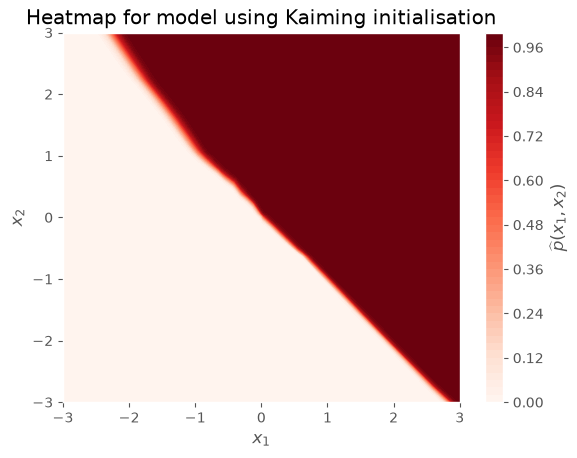

In [39]:
# num points in grid
this_num = 6 * 100 + 1

grid = np.linspace(-3., 3., num=this_num)
X_1g, X_2g = np.meshgrid(grid, grid)

X_1gf = np.reshape(X_1g, (this_num*this_num, 1))
X_2gf = np.reshape(X_2g, (this_num*this_num, 1))
Xf = np.concatenate((X_1gf, X_2gf), 1)

ppred = model_predict(f_k,Xf)

print("ppred.shape = ", ppred.shape)

ppred = np.reshape(ppred,(this_num, this_num))
print("ppred.shape = ", ppred.shape)
print("max = ", np.max(ppred))
print("min = ", np.min(ppred))

plt.contourf(X_1g, X_2g, ppred, 50, cmap="Reds")
cbar = plt.colorbar()
cbar.ax.set_ylabel(r"$\widehat{p}(x_1,x_2)$")
plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$")
plt.title("Heatmap for model using Kaiming initialisation")
plt.show()

<b>Claim:</b> Xavier initialization is suitable for networks with sigmoid or tanh activation functions, while Kaiming initialization is more appropriate for networks with ReLU activation functions

<b>Exercise:</b> Test this hypothesis

### Now look at Pytorch default initialisation

### initialisation of the ReLU layer

In [60]:
# dummy ReLU network
d = 1000

f = nn.Sequential(
    nn.Linear(1, d),
    nn.ReLU(),
    nn.Linear(d, d),
    nn.ReLU(),
    nn.Linear(d, 1)
)

Xavier a =  0.05477225575051661
<class 'numpy.ndarray'> (1000, 1000)
summary stats for input values
type : <class 'numpy.ndarray'>
shape : (1000000,)
min : -0.031622708
max : 0.03162276
mean : -8.16563e-07
std : 0.018258782
Histogram counts: [    0     0     0     0     0     0     0     0     0     0 12530 12518
 12516 12663 12478 12396 12563 12457 12597 12717 12582 12411 12147 12338
 12571 12355 12354 12412 12644 12462 12471 12481 12485 12568 12441 12431
 12649 12617 12691 12475 12492 12505 12482 12614 12549 12573 12310 12486
 12559 12589 12379 12683 12401 12312 12567 12595 12641 12519 12492 12390
 12500 12632 12379 12428 12397 12675 12499 12441 12469 12327 12536 12702
 12512 12413 12420 12599 12517 12392 12684 12354 12254 12589 12428 12309
 12507 12686 12474 12425 12601 12692     1     0     0     0     0     0
     0     0     0     0]


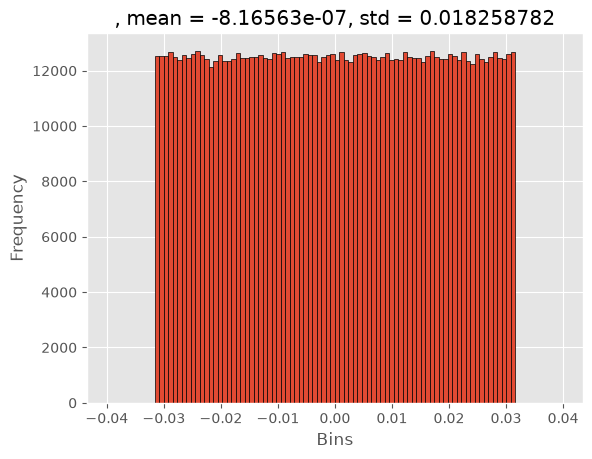

In [61]:
w_relu = f[2].weight.detach().numpy()

fan_out, fan_in = w_relu.shape
x_a = math.sqrt(6.0 / (fan_in + fan_out)) 
print("Xavier a = ", x_a)

print(type(w_relu), w_relu.shape)
plot_histogram_of_values(w_relu)

### initialisation of the Sigmoid layer

In [62]:
# dummy Sigmoid network
d = 1000

f = nn.Sequential(
    nn.Linear(1, d),
    nn.Sigmoid(),
    nn.Linear(d, d),
    nn.Sigmoid(),
    nn.Linear(d, 1)
)

<class 'numpy.ndarray'> (1000, 1000)
summary stats for input values
type : <class 'numpy.ndarray'>
shape : (1000000,)
min : -0.03162276
max : 0.031622767
mean : 5.697111e-06
std : 0.018253835
Histogram counts: [    0     0     0     0     0     0     0     0     0     0 12428 12230
 12521 12503 12390 12391 12440 12719 12517 12509 12540 12557 12531 12432
 12520 12466 12536 12631 12430 12721 12316 12778 12669 12595 12605 12425
 12487 12427 12447 12404 12430 12332 12591 12543 12440 12619 12516 12494
 12568 12528 12370 12273 12267 12552 12335 12472 12542 12602 12422 12483
 12589 12841 12363 12676 12305 12524 12478 12638 12516 12614 12403 12458
 12564 12473 12480 12790 12490 12285 12530 12660 12527 12372 12340 12241
 12532 12602 12524 12560 12549 12531     1     0     0     0     0     0
     0     0     0     0]


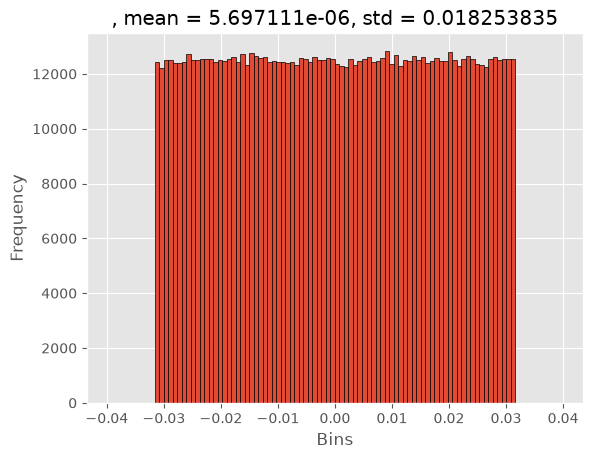

In [63]:
w_sigmoid = f[2].weight.detach().numpy()

fan_out, fan_in = w_sigmoid.shape

print(type(w_sigmoid), w_sigmoid.shape)
plot_histogram_of_values(w_sigmoid)

In [12]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import numpy as np

def train_model(
    model,
    X,
    y,
    loss_fn,
    optimizer,
    epochs=100,
    batch_size=32,
    metrics=None,
    X_val=None,
    y_val=None,
    validation_split=0.0,   
    verbose_every=10,
    device=None,
):
    """
    Generic training loop for a PyTorch model.

    ... (same as before) ...

    validation_split : float in [0.0, 1.0)
        Fraction of (X, y) to hold out as validation data, taken from the
        END of the dataset (matching Keras's default behavior). Ignored if
        X_val and y_val are both explicitly provided.
    """
    if not (0.0 <= validation_split < 1.0):
        raise ValueError("validation_split must be in [0.0, 1.0)")

    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)

    def to_tensor(a):
        if isinstance(a, np.ndarray):
            return torch.from_numpy(a).float()
        return a.float()

    X = to_tensor(X)
    y = to_tensor(y)

    # --- Handle validation_split (only if X_val/y_val not already given) ---
    if X_val is None and y_val is None and validation_split > 0.0:
        n_total = X.shape[0]
        n_val = int(round(n_total * validation_split))
        n_train = n_total - n_val

        X_val = X[n_train:]
        y_val = y[n_train:]
        X = X[:n_train]
        y = y[:n_train]
        print("n_total = ", n_total, "n_val = ", n_val, "n_train = ", n_train)

    dataset = TensorDataset(X, y)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    has_val = X_val is not None and y_val is not None
    if has_val:
        X_val = to_tensor(X_val).to(device)
        y_val = to_tensor(y_val).to(device)

    metrics = metrics or {}

    history = {"loss": []}
    history.update({name: [] for name in metrics})
    if has_val:
        history["val_loss"] = []
        history.update({f"val_{name}": [] for name in metrics})

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        running_metrics = {name: 0.0 for name in metrics}
        n_samples = 0

        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            y_pred = model(X_batch)
            y_batch = y_batch.unsqueeze(-1)
            loss = loss_fn(y_pred, y_batch)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            bs = X_batch.size(0)
            running_loss += loss.item() * bs
            for name, fn in metrics.items():
                running_metrics[name] += fn(y_pred, y_batch) * bs
            n_samples += bs

        epoch_loss = running_loss / n_samples
        #print("epoch = ", epoch, ", loss = ", epoch_loss) 
        history["loss"].append(epoch_loss)
        for name in metrics:
            val = running_metrics[name] / n_samples
            history[name].append(val)

        log_str = f"Epoch {epoch+1}/{epochs}, loss: {epoch_loss:.4f}"
        for name in metrics:
            log_str += f", {name}: {history[name][-1]:.4f}"

        if has_val:
            model.eval()
            with torch.no_grad():
                y_val_pred = model(X_val).squeeze()
                val_loss = loss_fn(y_val_pred, y_val).item()
                history["val_loss"].append(val_loss)
                #print("epoch = ", epoch, ", val_loss = ", val_loss) 
                log_str += f", val_loss: {val_loss:.4f}"
                for name, fn in metrics.items():
                    val_metric = fn(y_val_pred, y_val)
                    history[f"val_{name}"].append(val_metric)
                    log_str += f", val_{name}: {val_metric:.4f}"

        if verbose_every and (epoch + 1) % verbose_every == 0:
            print(log_str)

    return history

In [13]:
def model_predict(model, input_data):

	is_numpy_array = isinstance(input_data, np.ndarray)
	
	# 1. Make sure input_data is a float32 tensor
	if is_numpy_array:
		input_data = torch.from_numpy(input_data).float()
	else:
		input_data = input_data.float()

	# 2. Make sure it's on the same device as the model
	device = next(model.parameters()).device
	input_data = input_data.to(device)

	# 3. Set eval mode and disable gradient tracking for inference
	model.eval()
	with torch.no_grad():
		ppred = model(input_data)
		
	# 4. return as either numpy array or as tensor, depending on input type
	if is_numpy_array:
		# return as a numpy array
		ppred_np = ppred.cpu().numpy()
		return ppred_np
	else:
		return ppred

In [53]:
def plot_histogram_of_values( input_data : np.ndarray,
                              verbose : bool = False,
                              rescale_factor : float = 1.0,
                              num_bins : int = 100,
                              title_text : str = "",
                              image_name : str = "test"):

  input_values = input_data.flatten()

  print("summary stats for input values")
  print("type :", type(input_values))
  print("shape :", input_values.shape)
  print("min :", np.min(input_values))
  print("max :", np.max(input_values))
  num_dp = 4
  this_mean = np.mean(input_values)
  this_std = np.std(input_values)
  print("mean :", this_mean)
  print("std :", this_std)

  custom_bins = []
  this_min = np.min(input_values)
  this_max = np.max(input_values)
  this_mid = 0.5 * (this_min + this_max)
  min_value = this_mid + 1.25 * rescale_factor * (this_min - this_mid)
  max_value = this_mid + 1.25 * rescale_factor * (this_max - this_mid)
  #num_bins = 100
  step_size = (max_value - min_value) / num_bins
  for i in range(num_bins + 1):
    custom_bins.append(min_value + i * step_size)

  # Compute histogram with custom bins
  hist, bin_edges = np.histogram(input_values, bins=custom_bins)

  print("Histogram counts:", hist)

  # Plot histogram
  this_title = title_text + ", mean = " + str(this_mean) + ", std = " + str(this_std)
  plt.hist(input_values, bins=custom_bins, edgecolor='black')
  plt.title(this_title)
  plt.xlabel("Bins")
  plt.ylabel("Frequency")
  plt.savefig(image_name + '.pdf', dpi=300, bbox_inches='tight')
  plt.show()

  # Plot histogram
  #plt.hist(input_values, bins=custom_bins, edgecolor='black')
  #plt.xscale('log')
  #plt.yscale('log')
  #plt.title("Log/log plot : input values")
  #plt.xlabel("Bins")
  #plt.ylabel("Frequency")
  #plt.show()

  #return